# 01. Data cleaning
One row per England LSOA. Each step prints row counts so the cleaning is auditable.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
from scipy.spatial import cKDTree
RAW = Path("../data/raw"); OUT = Path("../data/clean"); OUT.mkdir(parents=True, exist_ok=True)
log = []  # cleaning log: (step, rows_before, rows_after)

## 1. LSOA boundaries (2021, BSC)
Keep England only (codes start with E), project to British National Grid (metres).

In [2]:
lsoa = gpd.read_file(RAW / "lsoa_boundaries_2021_bsc.geojson")
n0 = len(lsoa)
lsoa = lsoa[lsoa["LSOA21CD"].str.startswith("E")].to_crs(27700)
lsoa = lsoa[["LSOA21CD","LSOA21NM","RUC21CD","Urban_rura","geometry"]].copy()
lsoa["area_km2"] = lsoa.geometry.area / 1e6
lsoa["cent_x"] = lsoa.geometry.centroid.x   # geometric centroid (limitation)
lsoa["cent_y"] = lsoa.geometry.centroid.y
log.append(("Boundaries: keep England", n0, len(lsoa))); log[-1]

('Boundaries: keep England', 35672, 33755)

## 2. Population (mid-2024)

In [3]:
pop = pd.read_excel(RAW/"lsoa_population_2022_2024.xlsx", sheet_name="Mid-2024 LSOA 2021",
                    header=3, usecols=["LSOA 2021 Code","Total"])
pop.columns = ["LSOA21CD","population"]
pop.describe()

,population
count,35672.000000
mean,1732.638540
std,418.664074
min,935.000000
25%,1462.000000
50%,1647.000000
75%,1911.000000
max,9947.000000


## 3. IMD 2025

In [4]:
imd = pd.read_csv(RAW/"imd_2025.csv").rename(columns={
    "LSOA code (2021)":"LSOA21CD",
    "Index of Multiple Deprivation (IMD) Score":"imd_score",
    "Index of Multiple Deprivation (IMD) Decile (where 1 is most deprived 10% of LSOAs)":"imd_decile"
})[["LSOA21CD","imd_score","imd_decile"]]
imd.describe()

,imd_score,imd_decile
count,33755.000000,33755.000000
mean,21.669350,5.500074
std,15.689121,2.872324
min,0.165000,1.000000
25%,9.688500,3.000000
50%,17.450000,6.000000
75%,29.669500,8.000000
max,94.223000,10.000000


## 4. NaPTAN bus stops
Keep active stops of type BCT/BCS (on-street bus stops), drop rows without coordinates.

In [5]:
stops = pd.read_csv(RAW/"naptan.csv", low_memory=False,
                    usecols=["ATCOCode","StopType","Status","Easting","Northing"])
n0 = len(stops)
stops = stops[(stops.Status=="active") & stops.StopType.isin(["BCT","BCS"])]
log.append(("NaPTAN: active BCT/BCS", n0, len(stops)))
n1 = len(stops)
stops = stops.dropna(subset=["Easting","Northing"])
log.append(("NaPTAN: drop missing coordinates", n1, len(stops))); log[-2:]

[('NaPTAN: active BCT/BCS', 435837, 375442),
 ('NaPTAN: drop missing coordinates', 375442, 375442)]

## 5. Stops per LSOA and distance to nearest stop

In [6]:
sg = gpd.GeoDataFrame(stops, geometry=gpd.points_from_xy(stops.Easting, stops.Northing), crs=27700)
j = gpd.sjoin(sg, lsoa[["LSOA21CD","geometry"]], how="inner", predicate="within")
counts = j.groupby("LSOA21CD").size().rename("n_stops")
log.append(("Stops matched to an LSOA", len(stops), len(j)))
tree = cKDTree(np.c_[stops.Easting, stops.Northing])
lsoa["dist_nearest_stop_m"], _ = tree.query(np.c_[lsoa["cent_x"], lsoa["cent_y"]])
log[-1]

('Stops matched to an LSOA', 375442, 305361)

## 6. Join and checks

In [7]:
df = (lsoa.drop(columns="geometry").merge(pop,on="LSOA21CD",how="left")
      .merge(imd,on="LSOA21CD",how="left").merge(counts,on="LSOA21CD",how="left"))
df["n_stops"] = df["n_stops"].fillna(0).astype(int)
df["pop_density"] = df["population"] / df["area_km2"]
assert df["LSOA21CD"].is_unique
print("Missing values per column:"); print(df.isna().sum())
df.describe().T

Missing values per column:
LSOA21CD               0
LSOA21NM               0
RUC21CD                0
Urban_rura             0
area_km2               0
cent_x                 0
cent_y                 0
dist_nearest_stop_m    0
population             0
imd_score              0
imd_decile             0
n_stops                0
pop_density            0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
area_km2,33755.0,3.866667,13.219256,0.001253,0.259618,0.448895,1.248934,6.838543e+02
cent_x,33755.0,455132.708673,83680.966964,90551.169135,394100.954712,449846.722242,524559.506762,6.552306e+05
cent_y,33755.0,275499.465457,126713.638527,12821.392548,175323.616615,257421.095515,388686.482569,6.545635e+05
dist_nearest_stop_m,33755.0,274.950716,421.122320,0.485392,98.129397,168.153914,294.536266,4.576138e+04
population,33755.0,1736.634602,418.812960,935.000000,1466.000000,1650.000000,1913.000000,9.947000e+03
imd_score,33755.0,21.669350,15.689121,0.165000,9.688500,17.450000,29.669500,9.422300e+01
imd_decile,33755.0,5.500074,2.872324,1.000000,3.000000,6.000000,8.000000,1.000000e+01
n_stops,33755.0,9.046393,8.166752,0.000000,4.000000,7.000000,12.000000,1.250000e+02
pop_density,33755.0,5135.550849,11069.597706,2.197836,1358.018242,3700.451063,6358.599881,1.249327e+06


## 7. Save and cleaning log

In [8]:
df.to_parquet(OUT/"lsoa_base.parquet", index=False)
cleaning_log = pd.DataFrame(log, columns=["Step","Rows before","Rows after"])
cleaning_log.to_csv(OUT/"cleaning_log.csv", index=False)
cleaning_log

,Step,Rows before,Rows after
0,Boundaries: keep England,35672,33755
1,NaPTAN: active BCT/BCS,435837,375442
2,NaPTAN: drop missing coordinates,375442,375442
3,Stops matched to an LSOA,375442,305361


## 8. Quick look (for the report)

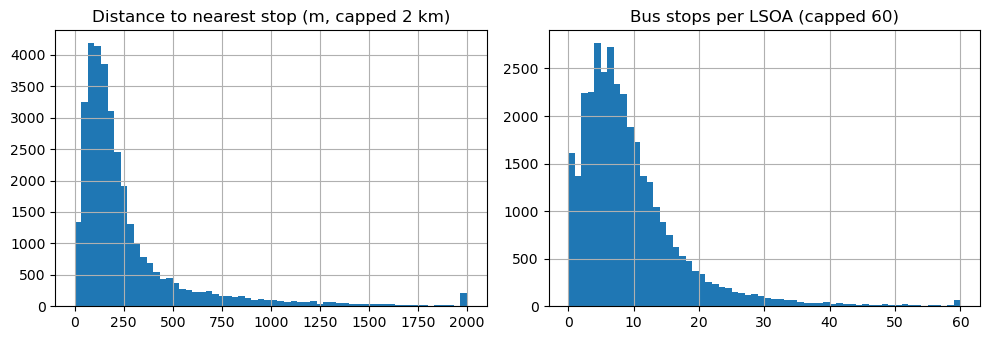

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2, figsize=(10,3.5))
df["dist_nearest_stop_m"].clip(upper=2000).hist(bins=60, ax=ax[0]); ax[0].set_title("Distance to nearest stop (m, capped 2 km)")
df["n_stops"].clip(upper=60).hist(bins=60, ax=ax[1]); ax[1].set_title("Bus stops per LSOA (capped 60)")
plt.tight_layout()